# ICT304 Assignment — YOLO11s
**FridgeChef — AI Ingredient Detection and Personalised Recipe Assistant**  
Parth Kotak · Wadiqa Baig · Syeda Masooma Zehra Naqvi

This notebook uses the submitted fine-tuned YOLO11s ingredient detector. The default run loads its saved weights, performs EDA, demonstrates a validation photograph and evaluates validation data. Training and new final testing require explicit configuration changes.

**Saved outputs are historical evidence from the original run.** Their old Colab paths, training messages and test plots are retained unchanged. The submission paths below apply to new runs. Rerunning a cell replaces its displayed output; keep the submitted copy for reference.

## Run in Google Colab
1. Upload the complete **Group Assignment Submission** folder to **My Drive**, keeping every folder inside **Code** together.
2. Open **Code → Fridge_YOLO → Final_YOLO11s.ipynb** with Google Colab.
3. Select **Runtime → Change runtime type → T4 GPU → Save**.
4. Leave the configuration in **evaluate** mode. If the submission is stored elsewhere, set **code_root** to its full **Code** folder path.
5. Select **Runtime → Run all** and approve the Drive mount. The notebook installs the pinned detector package only if needed. No training or upload prompt starts by default.
6. Find new results under **Code/lecturer_runs/yolo**, in a unique run folder. The submitted weights, dataset and evidence remain unchanged.

For EDA without a GPU, choose **preparation**. To repeat training, choose **train**; it starts from pretrained YOLO11s with the original 20-epoch, batch-16, patience-10 settings. For a fresh held-out test, use **evaluate**, the submitted checkpoint, and set both **final_test_enabled** and **settings_frozen** to **True**. Keep the evaluation settings unchanged.

A supplied photograph is optional: set **demo_image** to a path, or enable **upload_demo_image** in Colab. Otherwise a validation photograph is used.

In [ ]:
from pathlib import Path

# Change only this section when moving the submission or selecting a run.
CONFIG = {
    "code_root": None,
    "mode": "evaluate",
    "checkpoint": "Fridge_YOLO/best.pt",
    "device": 0,
    "image_size": 640,
    "batch_size": 16,
    "epochs": 20,
    "patience": 10,
    "save_period": 5,
    "flipud": 0.0,
    "translate": 0.2,
    "ultralytics_version": "8.4.171",
    "prediction_confidence": 0.25,
    "prediction_iou": 0.7,
    "demo_iou": 0.6,
    "ap_confidence": 0.001,
    "max_detections": 300,
    "final_test_enabled": False,
    "settings_frozen": False,
    "demo_image": None,
    "upload_demo_image": False,
}

In [ ]:
import importlib.util

IN_COLAB = importlib.util.find_spec("google.colab") is not None if importlib.util.find_spec("google") else False
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
else:
    print("Local session: Google Drive mounting is not needed.")

Mounted at /content/drive


In [ ]:
import hashlib
import json
import tempfile
from datetime import datetime, timezone
from uuid import uuid4


def find_code_root(override=None):
    """Return the submitted Code folder from an explicit path or known locations."""
    expected = ("Fridge_Combined_YOLO", "FridgeChef_RFDETR", "Fridge_YOLO")
    if override:
        candidates = [Path(override).expanduser().resolve()]
    else:
        parents = [Path.cwd(), *Path.cwd().parents]
        candidates = list(dict.fromkeys(candidate for parent in parents
                         for candidate in (parent, parent / "Code", parent / "Group Assignment Submission/Code")))
        candidates += [
            Path("/content/drive/MyDrive/Group Assignment Submission/Code"),
            Path("/content/drive/MyDrive/ICT304/Group Assignment Submission/Code"),
        ]
    for candidate in candidates:
        if all((candidate / name).is_dir() for name in expected):
            return candidate.resolve()
    raise FileNotFoundError("Set CONFIG['code_root'] to the Code folder containing all three model folders and the dataset.")


assert CONFIG["mode"] in {"preparation", "evaluate", "train"}
CODE_ROOT = find_code_root(CONFIG["code_root"])
DATASET_ROOT = CODE_ROOT / "Fridge_Combined_YOLO"
checkpoint_setting = Path(CONFIG["checkpoint"]).expanduser()
SUBMITTED_CHECKPOINT = checkpoint_setting if checkpoint_setting.is_absolute() else CODE_ROOT / checkpoint_setting
SUBMITTED_CHECKPOINT = SUBMITTED_CHECKPOINT.resolve()
assert SUBMITTED_CHECKPOINT.is_file(), f"Missing checkpoint: {SUBMITTED_CHECKPOINT}"
SUBMITTED_CHECKPOINT_SHA256 = "45adc4c4fd599c8b6067b2a027b6cfc7afff0b41a452e05bfd39b1e70ea9a927"
CHECKPOINT_SHA256 = hashlib.sha256(SUBMITTED_CHECKPOINT.read_bytes()).hexdigest()

# A unique output folder protects the submitted evidence from being overwritten.
RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ") + "_" + uuid4().hex[:6]
OUTPUT_DIR = CODE_ROOT / "lecturer_runs" / "yolo" / RUN_ID
OUTPUT_DIR.mkdir(parents=True, exist_ok=False)
WORK_DIR = Path(tempfile.mkdtemp(prefix="fridgechef_yolo_", dir="/content" if IN_COLAB else None))
RUNTIME_DATASET = WORK_DIR / "dataset"
RUNTIME_YAML = WORK_DIR / "data.runtime.yaml"
MODEL = None
model = None
TRAIN_RUN_DIR = None
best_model_path = str(SUBMITTED_CHECKPOINT)
(OUTPUT_DIR / "run_config.json").write_text(json.dumps({
    "configuration": CONFIG, "code_root": str(CODE_ROOT),
    "checkpoint": str(SUBMITTED_CHECKPOINT), "checkpoint_sha256": CHECKPOINT_SHA256,
    "recorded_at": datetime.now(timezone.utc).isoformat(),
}, indent=2))

In [ ]:
print("Submitted dataset:", DATASET_ROOT)
print("Selected checkpoint:", SUBMITTED_CHECKPOINT)
print("New outputs:", OUTPUT_DIR)
print("Run mode:", CONFIG["mode"])
print("Final test enabled:", CONFIG["final_test_enabled"])

Fridge_Combined_YOLO


## Dataset and EDA
EDA means exploratory data analysis: simple summaries of the prepared dataset. The first three plots are retained from the original notebook.

In [ ]:
import importlib.util
import subprocess
import sys

# Install only missing EDA dependencies in Colab.
eda_dependencies = {"yaml": "pyyaml", "pandas": "pandas", "plotly": "plotly==6.3.1", "matplotlib": "matplotlib"}
missing_eda = [package for module, package in eda_dependencies.items() if importlib.util.find_spec(module) is None]
if missing_eda:
    if not IN_COLAB:
        raise RuntimeError("Install these missing packages in your notebook environment: " + ", ".join(missing_eda))
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *missing_eda])

import os
import glob
import yaml
import pandas as pd
import plotly.express as px

# 1. Load class names from data.yaml
with open(DATASET_ROOT / 'data.yaml', 'r') as file:
    data_yaml = yaml.safe_load(file)

# Map class indices to class names
if isinstance(data_yaml.get('names'), dict):
    class_names = {int(key): name for key, name in data_yaml['names'].items()}
else:
    class_names = {i: name for i, name in enumerate(data_yaml.get('names', []))}
assert sorted(class_names) == list(range(42)), "The submitted dataset must contain the 42 canonical classes."

In [ ]:
# 2. Parse YOLO label files
splits = ['train', 'valid', 'test']
data = []

# Read the submitted labels without modifying the reviewed dataset.
base_path = str(DATASET_ROOT)

for split in splits:
    label_files = glob.glob(os.path.join(base_path, split, 'labels', '*.txt'))

    for file_path in label_files:
        try:
            # YOLO format: class x_center y_center width height
            df_temp = pd.read_csv(file_path, sep=r'\s+', header=None,
                                  names=['class_id', 'x_center', 'y_center', 'width', 'height'])
            if not df_temp.empty:
                df_temp['split'] = split
                data.append(df_temp)
        except pd.errors.EmptyDataError:
            # Empty labels represent reviewed negative images.
            pass

# Combine into a single DataFrame
df = pd.concat(data, ignore_index=True)
df['class_name'] = df['class_id'].map(class_names)

/tmp/ipykernel_3455/2718268167.py:21: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df = pd.concat(data, ignore_index=True)


In [ ]:
# 3. Class Distribution Bar Chart
class_counts = df.groupby(['class_name', 'split']).size().reset_index(name='count')
fig_classes = px.bar(class_counts, x='class_name', y='count', color='split',
                     title='Class Distribution by Dataset Split',
                     barmode='stack',
                     labels={'class_name': 'Fridge Item', 'count': 'Bounding Box Count'})
fig_classes.show()

In [ ]:
# 4. Bounding Box Dimensions (Width vs Height)
# Sample to keep the browser responsive if the merged dataset is large
df_sample = df.sample(n=min(5000, len(df)), random_state=42)
fig_scatter = px.scatter(df_sample, x='width', y='height', color='class_name',
                         title='Bounding Box Dimensions (Width vs. Height)',
                         labels={'width': 'Normalized Width', 'height': 'Normalized Height'},
                         opacity=0.6)
fig_scatter.update_layout(xaxis_range=[0, 1], yaxis_range=[0, 1])
fig_scatter.show()

In [ ]:
# 5. Spatial Heatmap of Object Centers
fig_heatmap = px.density_heatmap(df, x='x_center', y='y_center',
                                 title='Spatial Heatmap of Bounding Box Centers',
                                 labels={'x_center': 'Normalized X Center', 'y_center': 'Normalized Y Center'},
                                 nbinsx=40, nbinsy=40, color_continuous_scale='Plasma')
# Reverse Y-axis to match image coordinates (origin at top-left)
fig_heatmap.update_yaxes(autorange="reversed")
fig_heatmap.show()

## Additional dataset checks
These tables count images, reviewed negatives, independent groups, sources and sparse classes. A box may describe a package, bunch or ingredient batch. All paths use the submitted dataset.

In [ ]:
from pathlib import Path as ExtraPath
import pandas as extra_pd
import matplotlib.pyplot as extra_plot
from IPython.display import display as extra_display, Markdown as ExtraMarkdown

# Use the same submitted dataset as the original EDA cells.
extra_dataset_root = DATASET_ROOT
extra_provenance = extra_pd.read_csv(extra_dataset_root / "metadata/image_provenance.csv", keep_default_na=False)
extra_support = extra_pd.read_csv(extra_dataset_root / "metadata/class_split_support_v2.csv")
extra_splits = ["train", "valid", "test"]
print("Additional EDA dataset:", extra_dataset_root)

Additional EDA dataset: /Users/parthk/Documents/ICT304/ICT304 Project/Fridge_Combined_YOLO


### Image counts and reviewed negatives
A file count, an object count and an independent-group count describe different things. Related augmented variants increase stored image counts without adding independent photographs. An empty label file is a reviewed negative for the supported ingredient vocabulary; a missing label file is an error.

In [ ]:
extra_split_rows = []
for extra_split in extra_splits:
    extra_images = sorted(path for path in (extra_dataset_root / extra_split / "images").iterdir()
                          if path.suffix.lower() in {".jpg", ".jpeg", ".png", ".webp", ".bmp"})
    extra_labels = {path for path in (extra_dataset_root / extra_split / "labels").glob("*.txt")}
    extra_expected_labels = {extra_dataset_root / extra_split / "labels" / (path.stem + ".txt") for path in extra_images}
    assert extra_labels == extra_expected_labels, f"Missing or orphan annotation files in {extra_split}"
    extra_object_counts = [len([line for line in path.read_text().splitlines() if line.strip()])
                           for path in sorted(extra_labels)]
    extra_metadata = extra_provenance[extra_provenance.export_split == extra_split]
    assert {path.relative_to(extra_dataset_root).as_posix() for path in extra_images} == set(extra_metadata.image_path)
    assert sum(extra_object_counts) == int(extra_metadata.export_objects.sum())
    assert extra_object_counts.count(0) == int(extra_metadata.export_objects.eq(0).sum())
    extra_split_rows.append({"split": extra_split, "images": len(extra_images), "label_files": len(extra_labels),
        "objects": sum(extra_object_counts), "negative_images": extra_object_counts.count(0),
        "independent_groups": extra_metadata.split_dependency_id.nunique(), "scenes": extra_metadata.scene_id.nunique()})
extra_split_summary = extra_pd.DataFrame(extra_split_rows).set_index("split")
extra_display(extra_split_summary)
extra_display(ExtraMarkdown(
    f"There are **{extra_split_summary.images.sum():,} images**, **{extra_split_summary.objects.sum():,} annotations** "
    f"and **{extra_split_summary.negative_images.sum():,} reviewed negative images**. "
    f"The **{extra_split_summary.loc['train', 'images']:,} training files** represent "
    f"**{extra_split_summary.loc['train', 'independent_groups']:,} independent groups**. "
    "Every image has a matching label file, and the calculated totals agree with the frozen provenance."))

,images,label_files,objects,negative_images,independent_groups,scenes
split,,,,,,
train,3972,3972,41957,166,841,1323
valid,174,174,1492,18,174,174
test,97,97,899,11,97,97


There are **4,243 images**, **44,348 annotations** and **195 reviewed negative images**. The **3,972 training files** represent **841 independent groups**. Every image has a matching label file, and the calculated totals agree with the frozen provenance.

### Contributions from the source datasets
This table shows how the sources contribute files to each frozen split. The small chart focuses on training images; these file counts include existing related variants.

split,train,valid,test
dataset_name,,,
AIcook,2367,94,50
Fridge Food Images,940,64,35
Smart Fridge,665,16,12


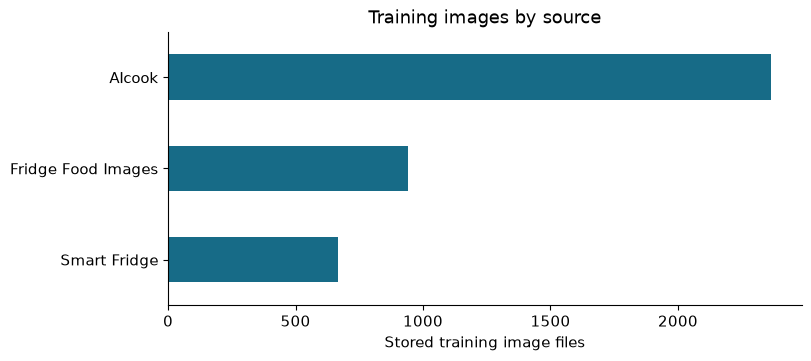

**AIcook contributes 59.6%** of the training files. The sources are therefore not equally represented; overall performance may hide differences between sources.

In [ ]:
extra_source_counts = extra_provenance.pivot_table(index="dataset_name", columns="export_split",
    values="source_image_id", aggfunc="size", fill_value=0).reindex(columns=extra_splits)
extra_source_counts.columns.name = "split"
extra_display(extra_source_counts)
with extra_plot.rc_context({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False}):
    extra_figure, extra_axis = extra_plot.subplots(figsize=(8, 3.5), layout="constrained")
    extra_source_counts["train"].sort_values().plot.barh(ax=extra_axis, color="#176B87")
    extra_axis.set(title="Training images by source", xlabel="Stored training image files", ylabel="")
    extra_plot.show()
    extra_plot.close(extra_figure)
extra_largest_source = extra_source_counts["train"].idxmax()
extra_largest_share = 100 * extra_source_counts.loc[extra_largest_source, "train"] / extra_source_counts["train"].sum()
extra_display(ExtraMarkdown(
    f"**{extra_largest_source} contributes {extra_largest_share:.1f}%** of the training files. "
    "The sources are therefore not equally represented; overall performance may hide differences between sources."))

### Classes with limited validation support
The original class chart counts boxes. Here we count the validation images containing each class, using the frozen support metadata. A class appearing in only a few images has a less stable performance estimate. Ten images is a descriptive reporting threshold, not a rule for deleting data.

In [ ]:
extra_validation_support = extra_support[extra_support.split == "valid"]
extra_sparse_validation = extra_validation_support[extra_validation_support.images < 10].sort_values(["images", "class_name"])
extra_display(extra_sparse_validation[["class_name", "images", "objects", "independent_dependency_groups"]].rename(
    columns={"images": "validation_images", "objects": "validation_boxes", "independent_dependency_groups": "independent_groups"}))
extra_display(ExtraMarkdown(
    f"**{len(extra_sparse_validation)} of {len(extra_validation_support)} classes** have fewer than ten validation images. "
    "Read their class-level scores alongside these support counts rather than relying only on the overall mAP. "
    "These additions do not change any images, annotations, split assignments or training settings."))

,class_name,validation_images,validation_boxes,independent_groups
115,cabbage,3,3,3
101,ham,4,4,4
116,bell_pepper,5,8,5
98,goat_cheese,5,5,5
118,ginger,9,14,9
119,green_chili,9,14,9


**6 of 42 classes** have fewer than ten validation images. Read their class-level scores alongside these support counts rather than relying only on the overall mAP. These additions do not change any images, annotations, split assignments or training settings.

## Load or train the detector
The submitted checkpoint contains the learned 42-class mapping. Temporary data copies keep framework caches outside the reviewed dataset. The training branch runs only when explicitly selected.

In [ ]:
# Keep framework caches and any image repairs outside the reviewed dataset.
def prepare_runtime_dataset(include_test=False, include_train=False):
    """Copy the requested splits to temporary storage and return their runtime YAML."""
    import shutil
    requested = ["valid"]
    if include_test:
        requested.append("test")
    if include_train:
        requested.append("train")
    for split in ("train", "valid", "test"):
        (RUNTIME_DATASET / split / "images").mkdir(parents=True, exist_ok=True)
        (RUNTIME_DATASET / split / "labels").mkdir(parents=True, exist_ok=True)
    for split in requested:
        for kind in ("images", "labels"):
            shutil.copytree(DATASET_ROOT / split / kind, RUNTIME_DATASET / split / kind, dirs_exist_ok=True)
    runtime_data = dict(data_yaml)
    runtime_data.update(path=str(RUNTIME_DATASET), train="train/images", val="valid/images", test="test/images")
    RUNTIME_YAML.write_text(yaml.safe_dump(runtime_data, sort_keys=False))
    return RUNTIME_YAML


def check_final_test_settings():
    """Reject a final test unless the submitted checkpoint and evaluation settings are fixed."""
    if not CONFIG["final_test_enabled"]:
        return
    assert CONFIG["mode"] == "evaluate", "Final testing uses saved weights, without training."
    assert CONFIG["settings_frozen"], "Set settings_frozen only when reproducing the submitted test configuration."
    assert CHECKPOINT_SHA256 == SUBMITTED_CHECKPOINT_SHA256, "The selected checkpoint differs from the submitted model."
    expected = {"image_size": 640, "batch_size": 16, "ap_confidence": 0.001,
                "max_detections": 300, "prediction_iou": 0.7, "prediction_confidence": 0.25}
    assert all(CONFIG[key] == value for key, value in expected.items()), "Restore the submitted evaluation settings before final testing."


check_final_test_settings()

In [ ]:
import subprocess
import sys
from importlib.metadata import version, PackageNotFoundError

if CONFIG["mode"] != "preparation":
    # Install only the pinned detector package when needed, retaining Colab's GPU runtime.
    try:
        installed_version = version("ultralytics")
    except PackageNotFoundError:
        installed_version = None
    if installed_version != CONFIG["ultralytics_version"]:
        if not IN_COLAB:
            raise RuntimeError("Use Colab for GPU execution, or select preparation for local EDA.")
        import torch
        import torchvision
        constraint_file = WORK_DIR / "runtime_constraints.txt"
        constraint_file.write_text(f"torch=={torch.__version__}\ntorchvision=={torchvision.__version__}\n")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", "-c", str(constraint_file),
                               f"ultralytics=={CONFIG['ultralytics_version']}"])
    import torch
    from ultralytics import YOLO
    assert torch.cuda.is_available(), "Select a GPU runtime in Colab, or use preparation mode for EDA only."
    assert CONFIG["device"] == 0, "This notebook uses the first Colab CUDA GPU explicitly."
    (OUTPUT_DIR / "environment.json").write_text(json.dumps({
        "python": sys.version, "torch": torch.__version__, "ultralytics": version("ultralytics"),
        "device": torch.cuda.get_device_name(0), "checkpoint_sha256": CHECKPOINT_SHA256,
    }, indent=2))
    print("GPU:", torch.cuda.get_device_name(0))
    prepare_runtime_dataset(include_test=CONFIG["final_test_enabled"], include_train=CONFIG["mode"] == "train")

    if CONFIG["mode"] == "train":
        # These are the original training settings. Training is an explicit opt-in.
        model = YOLO(str(WORK_DIR / "yolo11s.pt"))
        results = model.train(
            data=str(RUNTIME_YAML), epochs=CONFIG["epochs"], patience=CONFIG["patience"],
            save_period=CONFIG["save_period"], imgsz=CONFIG["image_size"], batch=CONFIG["batch_size"],
            save=True, flipud=CONFIG["flipud"], translate=CONFIG["translate"],
            device=CONFIG["device"], project=str(OUTPUT_DIR), name="training", exist_ok=False,
        )
        TRAIN_RUN_DIR = Path(model.trainer.save_dir)
        best_model_path = str(TRAIN_RUN_DIR / "weights" / "best.pt")
    else:
        print("Loading the submitted detector; training is skipped.")
    model = YOLO(best_model_path)
    assert model.names == class_names, "The checkpoint class mapping does not match the dataset."
else:
    print("Preparation mode: EDA only; model loading and GPU execution are skipped.")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 5.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 82.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 95.2/95.2 kB 12.0 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Starting Fridge Inventory Object Detection Training...
Ultralytics 8.4.171 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=

In [ ]:
# New training checkpoints are already saved to the unique output folder on Drive.
if TRAIN_RUN_DIR is not None:
    print("New best checkpoint:", best_model_path)
    print("Latest training checkpoint:", TRAIN_RUN_DIR / "weights" / "last.pt")
else:
    print("Submitted checkpoint retained at:", SUBMITTED_CHECKPOINT)
print("The submitted checkpoint is never overwritten or downloaded automatically.")

Found best model at: /content/runs/detect/fridge_inventory/weights/best.pt
All checkpoints successfully backed up to Google Drive: /content/drive/MyDrive/ICT304/Fridge_YOLO_Weights
Initiating browser download for best.pt...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Training evidence
The saved plots below come from the original training run. Evaluation mode recovers the original training history from the submitted checkpoint. A new training run produces its own history. The comparison table reads the submitted ensemble results.

Checking results in: /content/runs/detect/fridge_inventory

--- Standard Training Results Summary ---


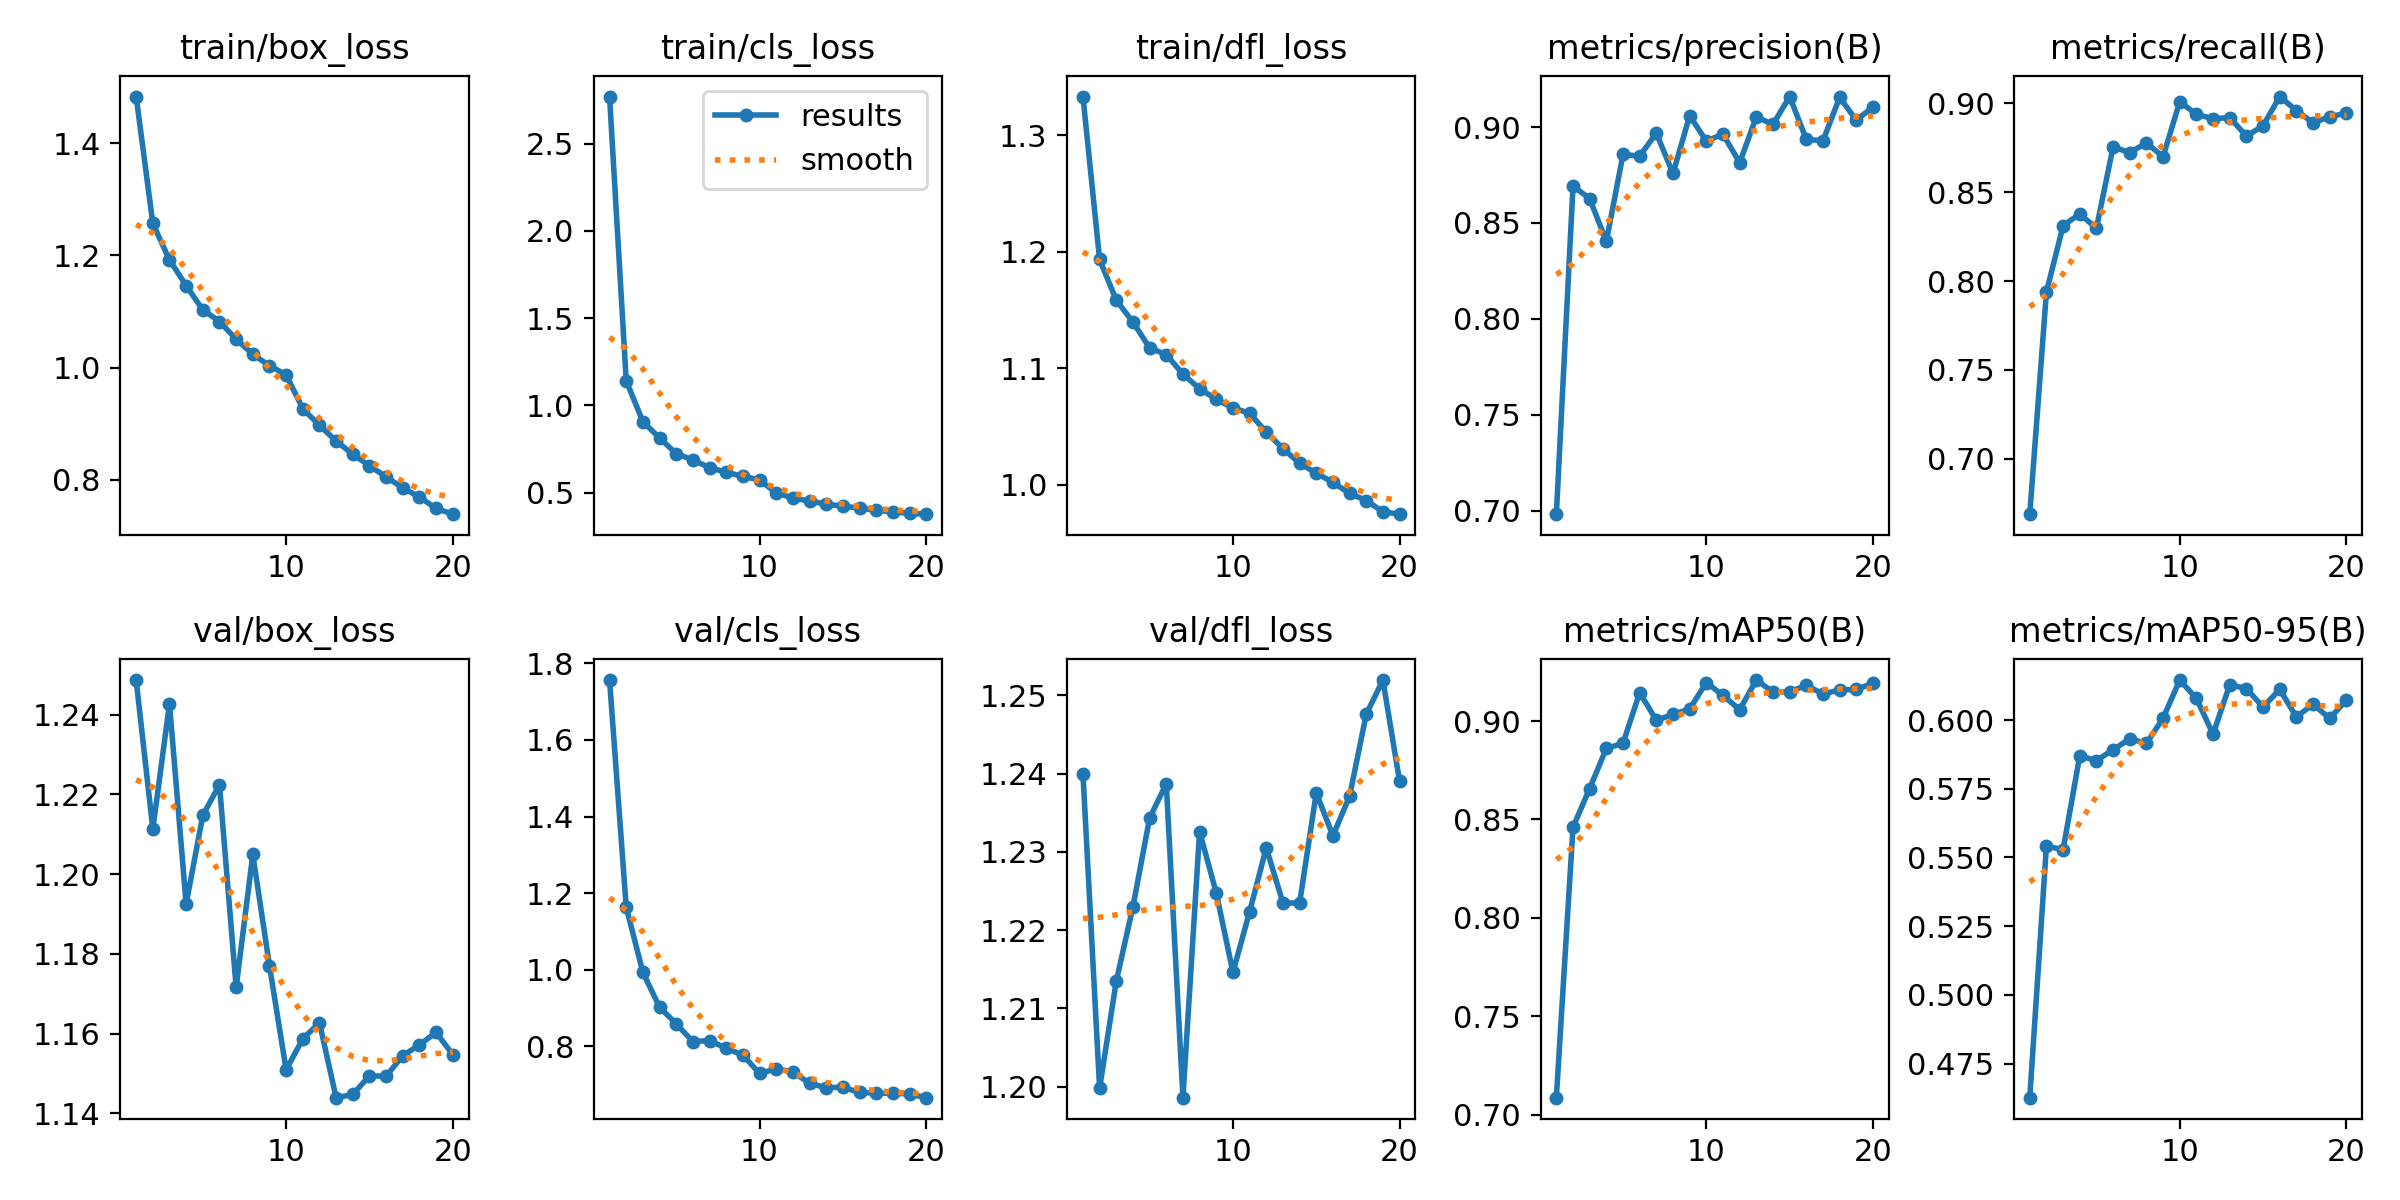


--- Confusion Matrix ---


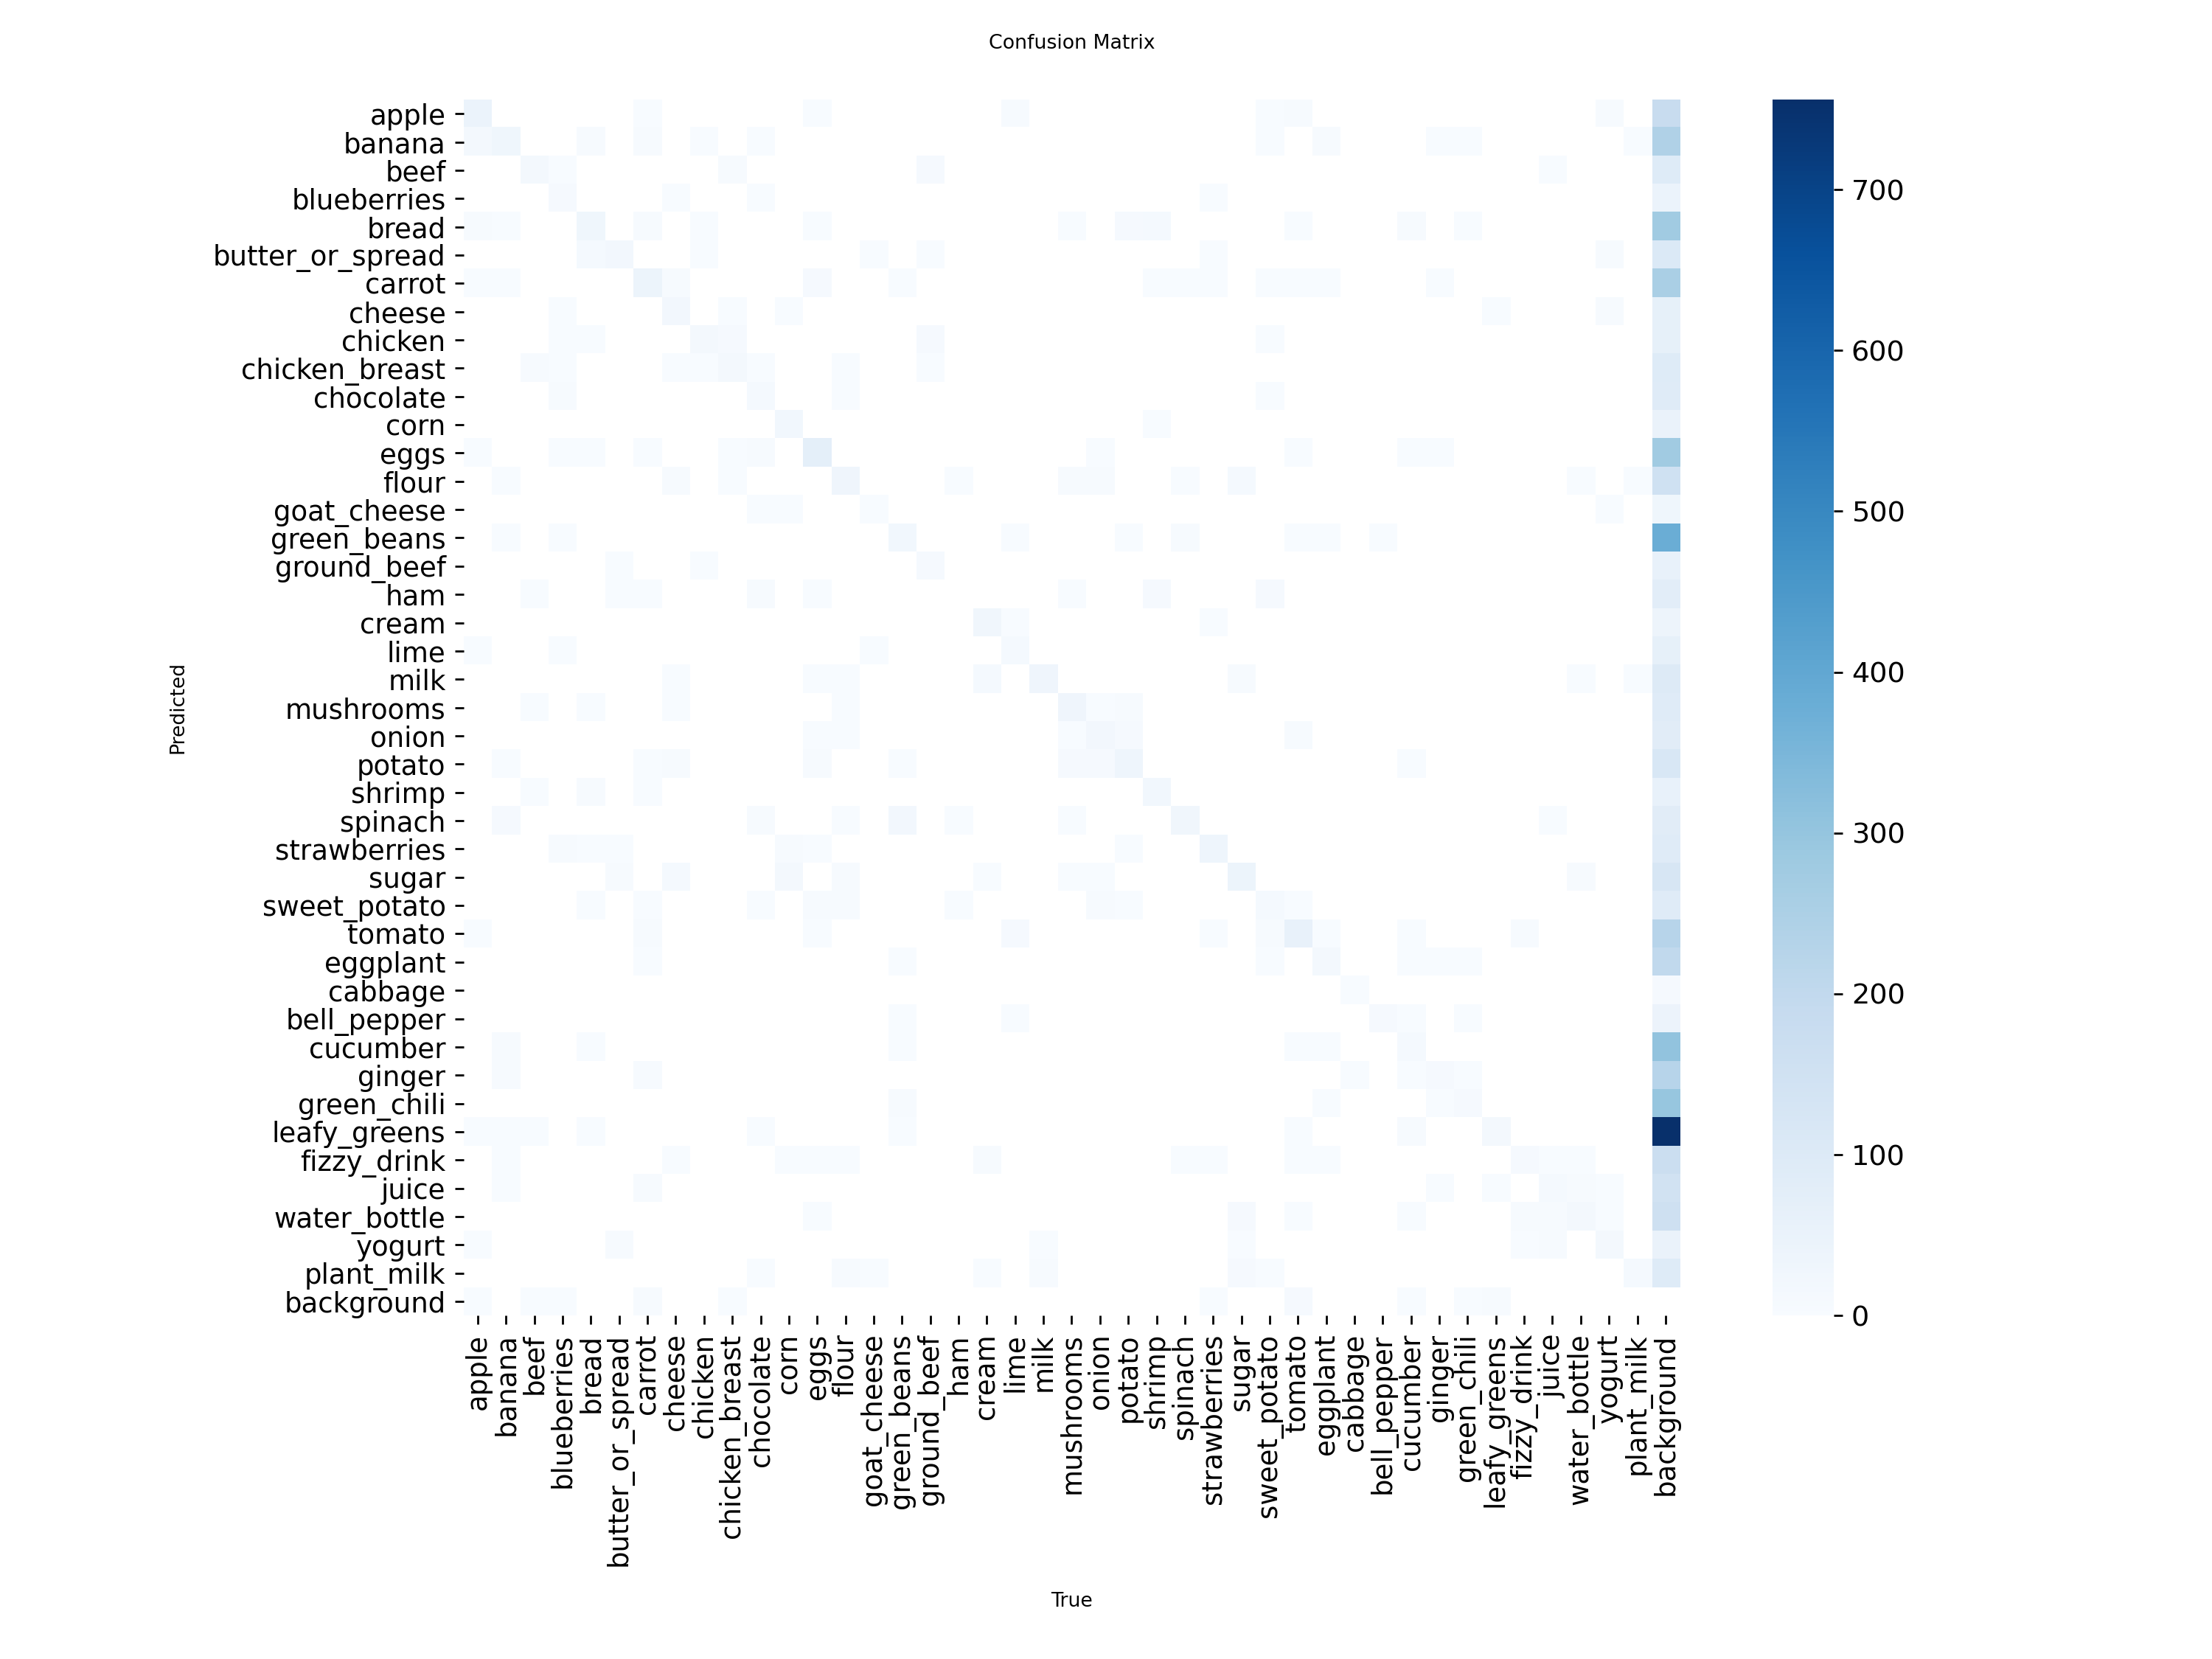


--- Custom Detailed Metrics Plots ---


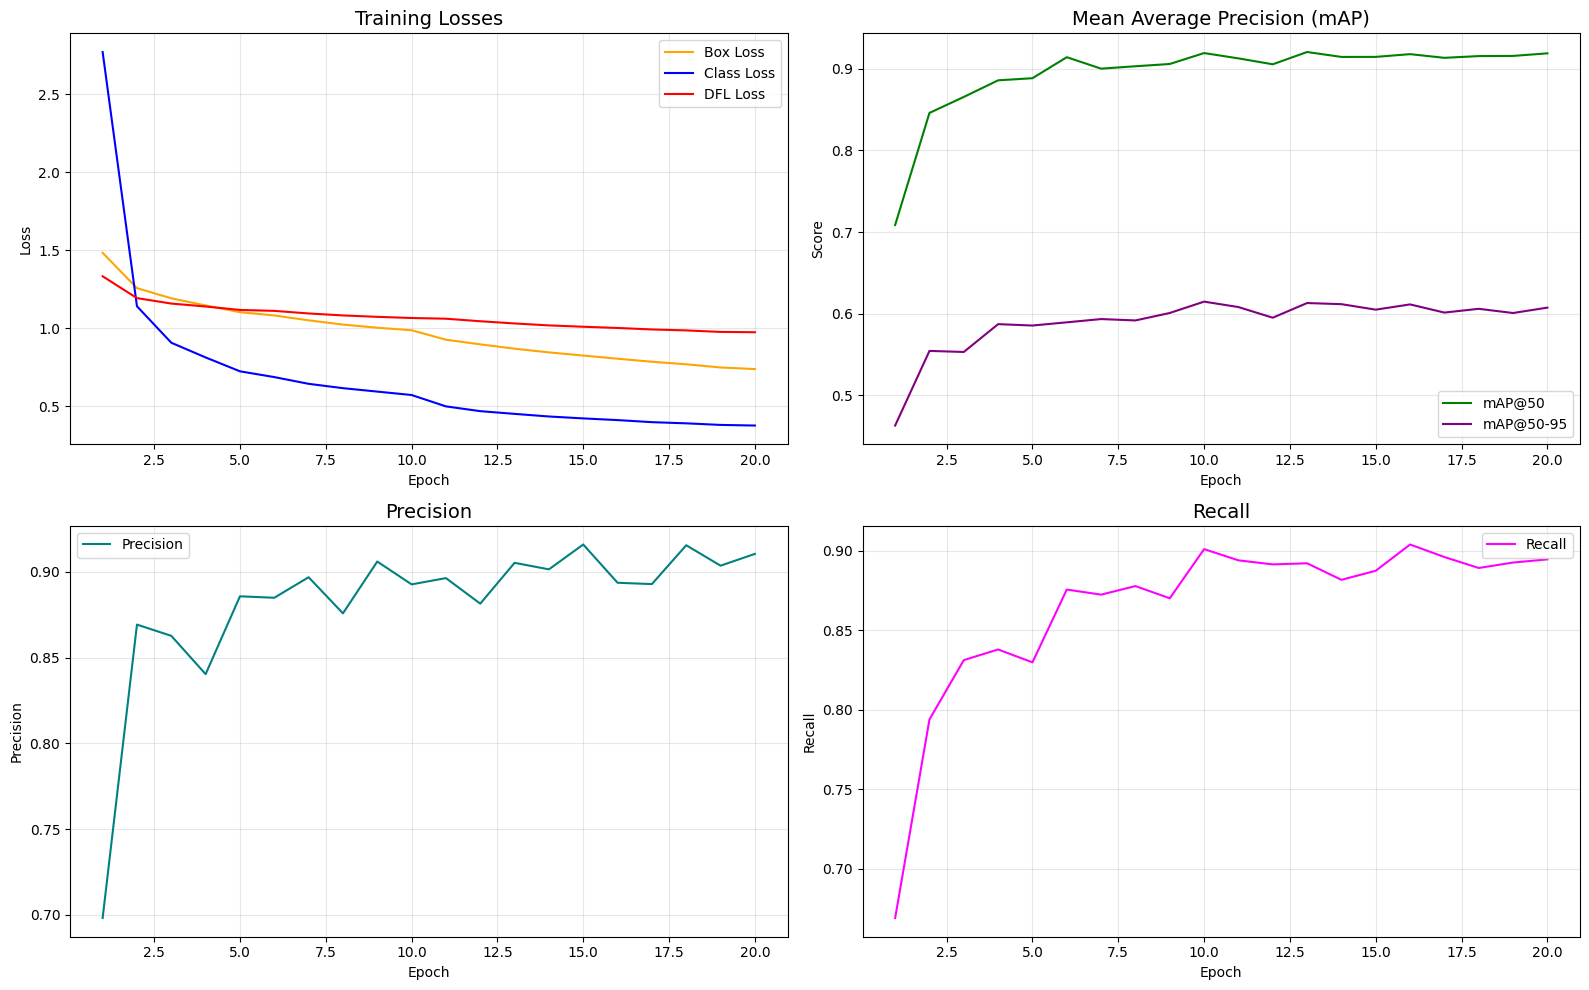

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

# The submitted checkpoint retains its full training history.
history = None
if TRAIN_RUN_DIR is not None:
    csv_path = TRAIN_RUN_DIR / "results.csv"
    if csv_path.is_file():
        history = pd.read_csv(csv_path)
    for filename in ("results.png", "confusion_matrix.png"):
        figure_path = TRAIN_RUN_DIR / filename
        if figure_path.is_file():
            display(Image(filename=str(figure_path)))
elif model is not None:
    saved_history = model.ckpt.get("train_results")
    if saved_history:
        history = pd.DataFrame(saved_history)
        print("Original training history recovered from the submitted checkpoint.")

if history is not None:
    history.columns = history.columns.str.strip()
    history.to_csv(OUTPUT_DIR / "training_history.csv", index=False)
    figure, axes = plt.subplots(2, 2, figsize=(16, 10))
    plot_columns = [
        ("Training losses", ["train/box_loss", "train/cls_loss", "train/dfl_loss"]),
        ("Validation mAP", ["metrics/mAP50(B)", "metrics/mAP50-95(B)"]),
        ("Validation precision", ["metrics/precision(B)"]),
        ("Validation recall", ["metrics/recall(B)"]),
    ]
    for axis, (title, columns) in zip(axes.ravel(), plot_columns):
        for column in columns:
            if column in history:
                axis.plot(history["epoch"], history[column], label=column)
        axis.set(title=title, xlabel="Epoch")
        axis.legend()
        axis.grid(True, alpha=0.3)
    figure.tight_layout()
    figure.savefig(OUTPUT_DIR / "training_history.png", dpi=140)
    plt.show()
else:
    print("Preparation mode: checkpoint history loading is skipped. Original plots remain in the saved notebook.")

# This table uses the ensemble notebook's common evaluation protocol.
submitted_comparison = CODE_ROOT / "FridgeChef_Ensemble/evaluation_results/20261002T234626Z_a4f9fe/valid_comparison.csv"
if submitted_comparison.is_file():
    submitted_metrics = pd.read_csv(submitted_comparison)
    print("Recorded YOLO validation result from the submitted common-protocol comparison:")
    display(submitted_metrics[submitted_metrics["model"].eq("YOLO11s")])

## Optional final-test predictions
New test predictions require frozen settings and explicit final-test enablement. The original saved test output remains evidence of the completed experiment.


image 1/97 /content/dataset/Fridge_Combined_YOLO/test/images/ai__00f0b33248cb5d377362.jpg: 640x640 1 apple, 1 bread, 1 butter_or_spread, 1 carrot, 1 cheese, 1 chicken, 1 chicken_breast, 1 eggs, 2 flours, 1 green_beans, 1 ground_beef, 1 shrimp, 1 strawberries, 1 sweet_potato, 1 tomato, 36.8ms
image 2/97 /content/dataset/Fridge_Combined_YOLO/test/images/ai__036f5d58c3180598ece9.jpg: 640x640 1 apple, 2 beefs, 1 bread, 1 butter_or_spread, 1 cheese, 1 eggs, 1 flour, 1 green_beans, 1 onion, 1 shrimp, 41.9ms
image 3/97 /content/dataset/Fridge_Combined_YOLO/test/images/ai__0b53a097eb75ee1ea4be.jpg: 640x640 1 apple, 1 banana, 1 blueberries, 1 butter_or_spread, 2 carrots, 1 cheese, 1 chicken, 1 corn, 1 flour, 1 goat_cheese, 1 green_beans, 1 ham, 1 cream, 1 lime, 1 milk, 1 mushrooms, 1 onion, 1 potato, 1 shrimp, 1 spinach, 1 strawberries, 2 sugars, 1 sweet_potato, 1 tomato, 1 plant_milk, 30.3ms
image 4/97 /content/dataset/Fridge_Combined_YOLO/test/images/ai__0d291ec9dfe000176d30.jpg: 640x640 2 a

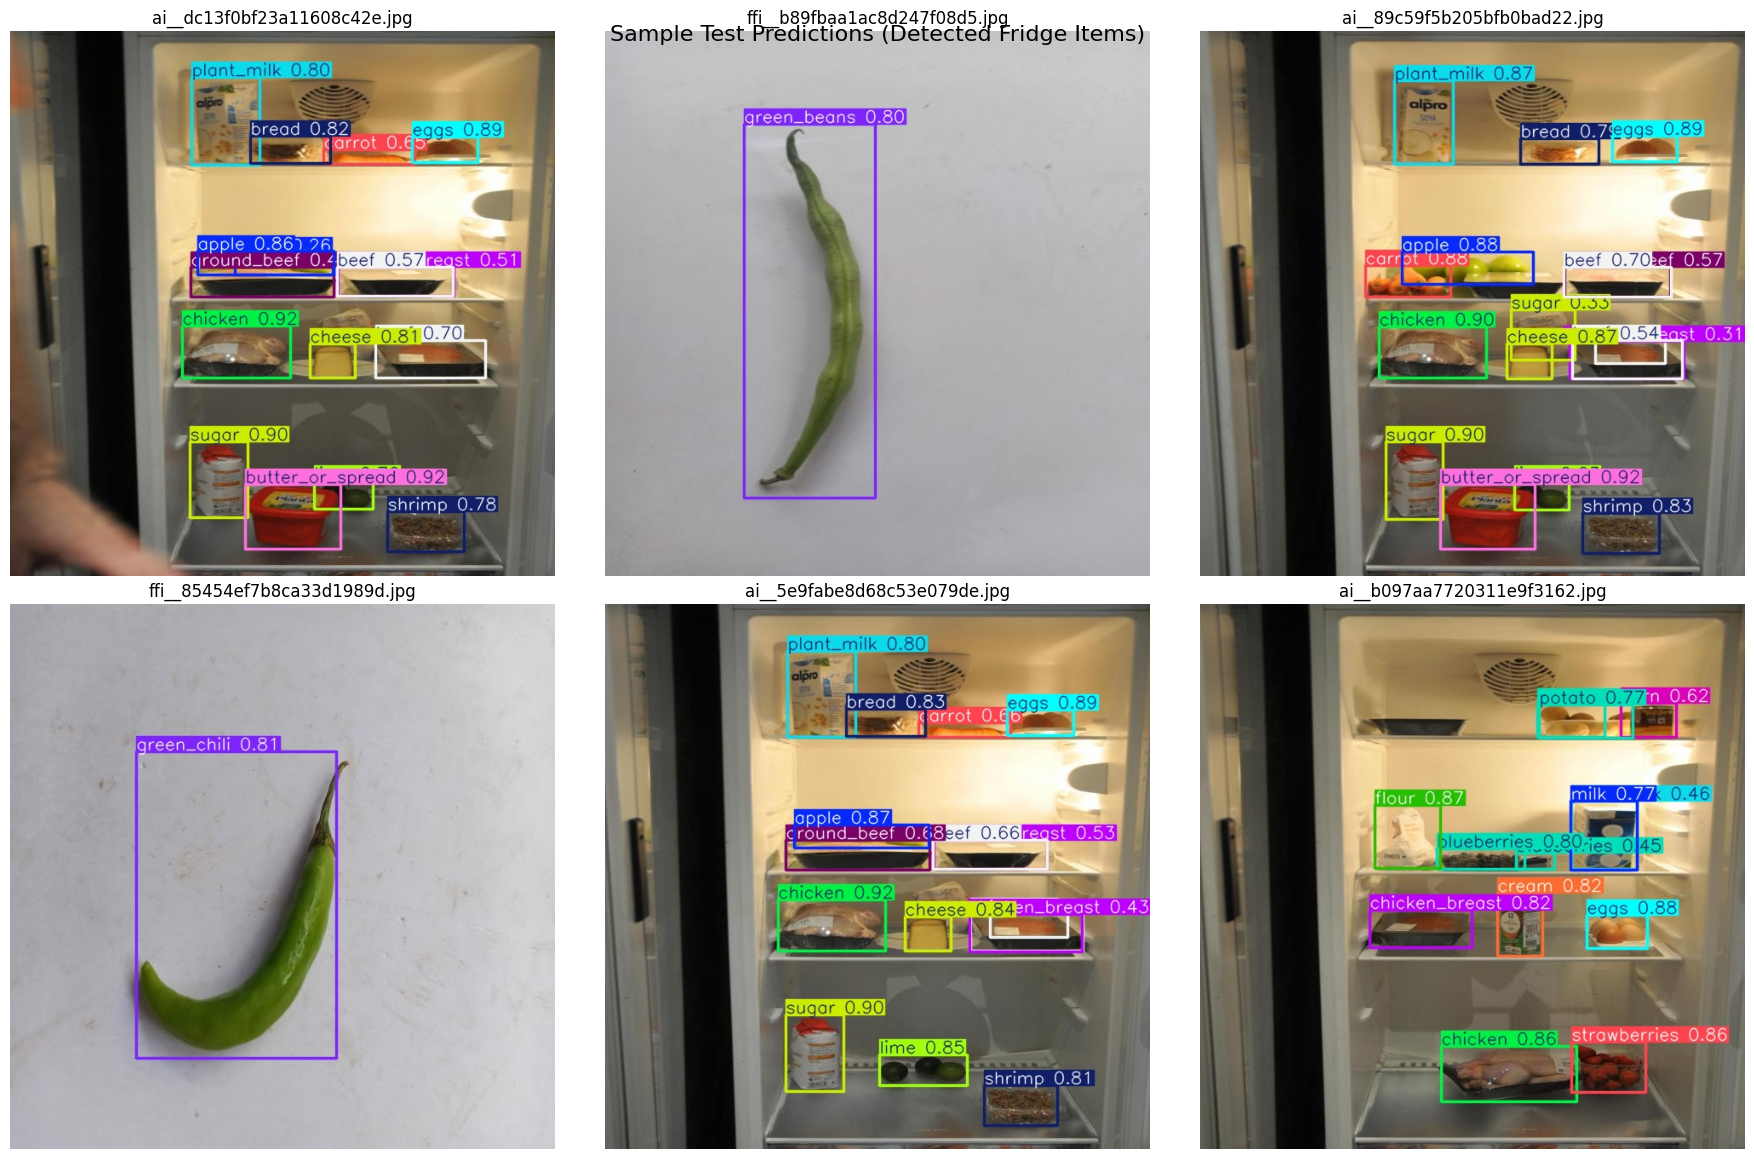

In [ ]:
import random
import matplotlib.pyplot as plt
import cv2

if model is not None and CONFIG["final_test_enabled"]:
    check_final_test_settings()
    pred_results = model.predict(
        source=str(RUNTIME_DATASET / "test/images"), imgsz=CONFIG["image_size"],
        conf=CONFIG["prediction_confidence"], iou=CONFIG["prediction_iou"], max_det=CONFIG["max_detections"],
        save=True, device=CONFIG["device"], project=str(OUTPUT_DIR), name="test_predictions", exist_ok=False,
    )
    pred_dir = Path(pred_results[0].save_dir)
    annotated_images = sorted(path for path in pred_dir.iterdir() if path.suffix.lower() in {".jpg", ".jpeg", ".png"})
    print("Test images predicted:", len(pred_results))
    sample_images = random.Random(304).sample(annotated_images, min(6, len(annotated_images)))
    fig, axs = plt.subplots(2, 3, figsize=(18, 12))
    for axis in axs.ravel():
        axis.axis("off")
    for axis, image_path in zip(axs.ravel(), sample_images):
        axis.imshow(cv2.cvtColor(cv2.imread(str(image_path)), cv2.COLOR_BGR2RGB))
        axis.set_title(image_path.name, fontsize=10)
    plt.suptitle("Final test predictions")
    plt.tight_layout()
    plt.show()
else:
    print("New test predictions are disabled. The saved outputs below document the original test run.")

## Ingredient demonstration
The table combines repeated labels. A detected box does not establish food quantity, freshness or expiry.

Please upload a picture of your fridge:


Saving 015.jpg to 015.jpg

Processing '015.jpg'...

image 1/1 /content/015.jpg: 640x480 9 apples, 1 bread, 1 butter_or_spread, 3 milks, 2 cucumbers, 1 fizzy_drink, 1 juice, 1 water_bottle, 1 yogurt, 19.3ms
Speed: 3.6ms preprocess, 19.3ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 480)

           DETECTED FRIDGE INVENTORY          


,Item,Count,Avg_Confidence
0,apple,9,0.515333
6,milk,3,0.481000
3,cucumber,2,0.469500
2,butter_or_spread,1,0.274000
1,bread,1,0.252000
4,fizzy_drink,1,0.593000
5,juice,1,0.333000
7,water_bottle,1,0.422000
8,yogurt,1,0.759000



Total items identified: 20


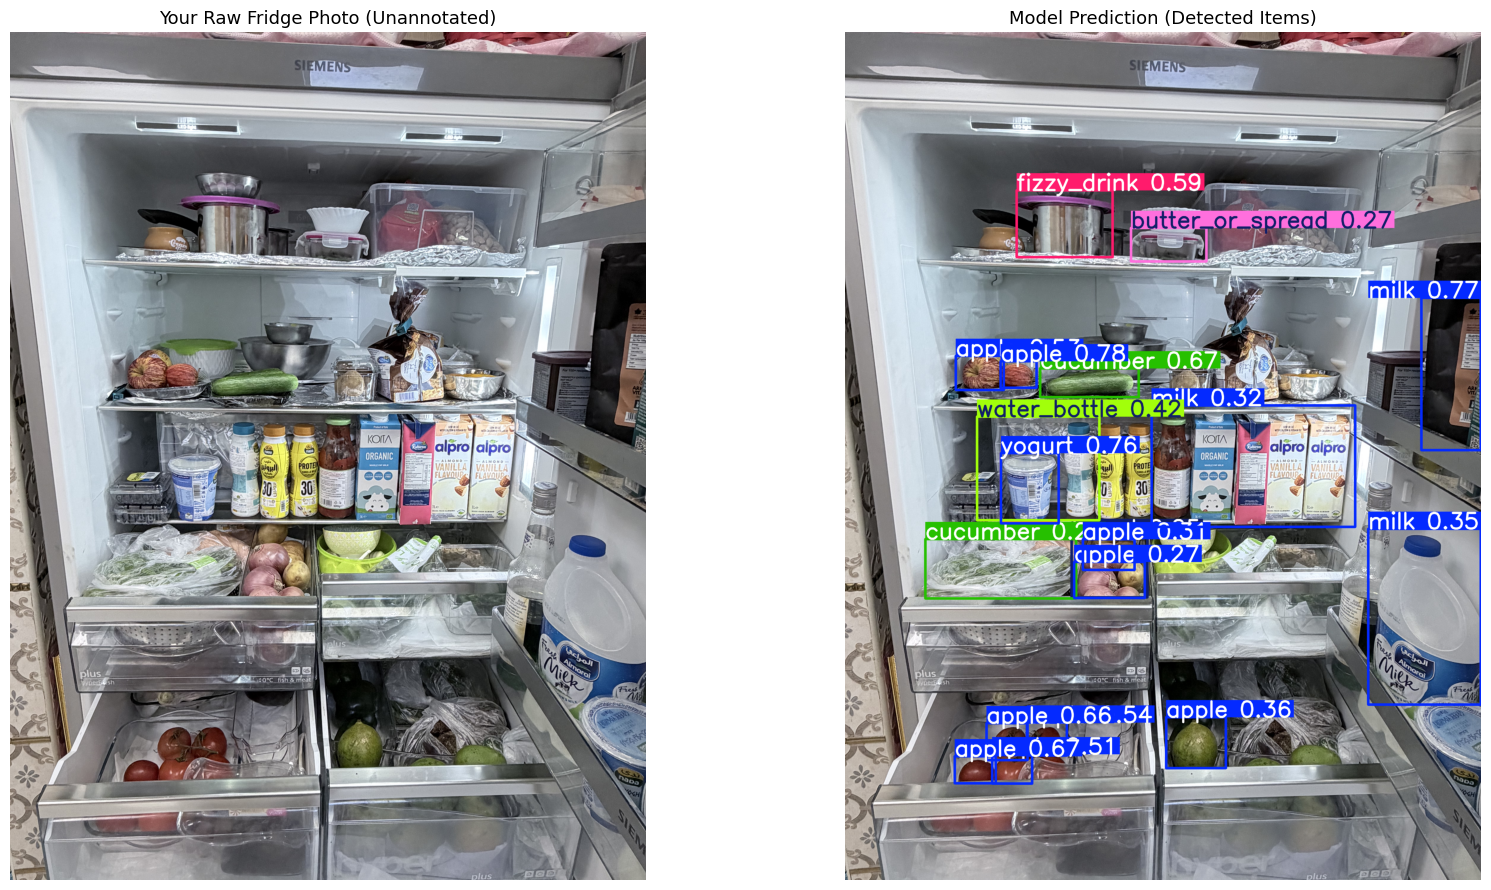

In [ ]:
import cv2
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

if model is not None:
    if CONFIG["upload_demo_image"]:
        assert IN_COLAB, "For a local photograph, set demo_image to its path."
        from google.colab import files
        print("Upload a photograph for the demonstration.")
        uploaded = files.upload()
        raw_img_path = Path(next(iter(uploaded))) if uploaded else None
    elif CONFIG["demo_image"]:
        image_setting = Path(CONFIG["demo_image"]).expanduser()
        raw_img_path = image_setting if image_setting.is_absolute() else CODE_ROOT / image_setting
    else:
        raw_img_path = sorted((DATASET_ROOT / "valid/images").glob("*.jpg"))[0]

    if raw_img_path is not None:
        assert raw_img_path.is_file(), f"Missing photograph: {raw_img_path}"
        assert not raw_img_path.resolve().is_relative_to((DATASET_ROOT / "test").resolve()), "Use a validation or supplied photograph for the demonstration."
        results = model.predict(source=str(raw_img_path), imgsz=CONFIG["image_size"],
                                conf=CONFIG["prediction_confidence"], iou=CONFIG["demo_iou"],
                                max_det=CONFIG["max_detections"], save=False, device=CONFIG["device"])
        result = results[0]
        detected_data = [{"class_id": int(box.cls[0].item()),
                          "Item": model.names[int(box.cls[0].item())],
                          "Confidence": float(box.conf[0].item())} for box in result.boxes]
        df_detections = pd.DataFrame(detected_data, columns=["class_id", "Item", "Confidence"])
        if not df_detections.empty:
            inventory_summary = (df_detections.groupby(["class_id", "Item"])
                .agg(Detected_boxes=("Item", "count"), Avg_Confidence=("Confidence", "mean"))
                .reset_index().sort_values(by="Detected_boxes", ascending=False))
            display(inventory_summary)
            print("Supported ingredients:", inventory_summary.Item.tolist())
        else:
            print("No supported ingredients detected above the configured confidence threshold.")
        print("Boxes can represent packages or batches; counts do not establish quantity or freshness.")
        raw_rgb = cv2.cvtColor(cv2.imread(str(raw_img_path)), cv2.COLOR_BGR2RGB)
        annotated_rgb = cv2.cvtColor(result.plot(), cv2.COLOR_BGR2RGB)
        fig, axes = plt.subplots(1, 2, figsize=(18, 9))
        axes[0].imshow(raw_rgb)
        axes[0].set_title("Input photograph")
        axes[1].imshow(annotated_rgb)
        axes[1].set_title("Predicted ingredients")
        for axis in axes:
            axis.axis("off")
        plt.tight_layout()
        plt.show()
else:
    print("Preparation mode: prediction demonstration skipped.")

## Evaluation
The default new evaluation uses validation data. Final testing uses the same saved checkpoint only after the two test controls are enabled. Mean average precision measures detection quality; it is not classification accuracy. Native Ultralytics precision and recall can differ from the fixed-threshold comparison in the ensemble notebook.

In [ ]:
if model is not None:
    check_final_test_settings()
    evaluation_split = "test" if CONFIG["final_test_enabled"] else "val"
    # AP keeps low-scoring predictions and does not use the photograph's display threshold.
    metrics = model.val(
        data=str(RUNTIME_YAML), split=evaluation_split, device=CONFIG["device"],
        imgsz=CONFIG["image_size"], batch=CONFIG["batch_size"], conf=CONFIG["ap_confidence"],
        iou=CONFIG["prediction_iou"], max_det=CONFIG["max_detections"], quantize=32,
        project=str(OUTPUT_DIR), name="final_test" if evaluation_split == "test" else "validation",
        exist_ok=False,
    )
    metric_summary = {"split": evaluation_split, "checkpoint": str(Path(best_model_path).resolve()),
        "checkpoint_sha256": hashlib.sha256(Path(best_model_path).read_bytes()).hexdigest(),
        "mAP50": float(metrics.box.map50), "mAP50_95": float(metrics.box.map),
        "precision": float(metrics.box.mp), "recall": float(metrics.box.mr)}
    (OUTPUT_DIR / "detection_metrics.json").write_text(json.dumps(metric_summary, indent=2))
    print("Evaluation split:", evaluation_split)
    print(f"mAP50: {metrics.box.map50 * 100:.2f}%")
    print(f"mAP50–95: {metrics.box.map * 100:.2f}%")
    print(f"Precision: {metrics.box.mp * 100:.2f}%")
    print(f"Recall: {metrics.box.mr * 100:.2f}%")
else:
    print("Preparation mode: GPU validation and final testing skipped.")

Ultralytics 8.4.171 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 100 layers, 9,429,054 parameters, 0 gradients, 21.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1485.4±317.2 MB/s, size: 38.8 KB)
val: Scanning /content/dataset/Fridge_Combined_YOLO/test/labels... 97 images, 11 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 97/97 1.8Kit/s 0.1s
val: New cache created: /content/dataset/Fridge_Combined_YOLO/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 1.3it/s 5.2s
                   all         97        899      0.859      0.907      0.916      0.624
                 apple         35         61       0.81      0.967      0.908       0.55
                banana         17         20       0.81       0.85      0.899      0.549
                  beef         30         30      0.752      0.967       0.91        0.3
           blueberries         23         23

## References and runtime note
[Ultralytics training](https://docs.ultralytics.com/modes/train/) · [Ultralytics validation](https://docs.ultralytics.com/modes/val/)

The submission check verified notebook structure, portable paths, checkpoint identity and CPU preparation. A new Colab GPU evaluation was not executed during handoff. Runtime and small numerical differences depend on the installed CUDA stack and GPU. The existing outputs remain the results of the original recorded runs.